# 01 · Preprocessing — Zhang 2021 Renal Cell Carcinoma (malignant compartment)

Isolate the malignant compartment, threshold thin samples, integrate patients (Harmony), embed,
and certify **Gate 1** (sample-mixed + continuous) on the regenerated embedding itself. Zhang et al.
(2021) profiled clear-cell RCC by 10x, calling malignant cells and annotating each with a 3CA
**meta-program** (`mp_top`). Every tunable choice is **derived from this dataset**, not inherited
from the Puram/Bi anchors:

- **Sample threshold** — largest *multiplicative* cliff in the sorted per-sample counts (the natural
  tumour/spillover separatrix), geometric-mean cut when a dominant cliff exists.
- **Integration strength `theta`** — swept and read on **manifold connectivity** (single connected
  component) with the same-sample-neighbour scalar only as a tie-break, never as the gate.
- **Island removal** — per-patient kNN-purity; a patient standing off the pack is an unintegrable
  island and removed. Here none qualifies.
- **House orientation** — one rigid rotation of the diagonal developmental axis to horizontal
  (origin on the left), derived once here from module geography and re-used by 02/03/04.

Deliverable: `processed.h5ad`, `samples.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Zhang2021_Kidney | category: Kidney


### Load the malignant compartment
Zhang et al. supply a per-cell `cell_type` in which **Malignant** is an explicit publication call;
the loader exposes it as `celltype`, taken directly (per protocol). Counts are `normalize_total` +
`log1p` by the loader. Each malignant cell also carries a publication **meta-program** (`mp_top`:
Stress / Interferon-MHC-II / Glutathione / EMT-III …) — the publication's transcriptional-state
calls, carried through as the annotation source, and a cell-cycle phase.

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
print('publication meta-programs (mp_top):', adata.obs['mp_top'].value_counts().head(6).to_dict())
print('cell-cycle phase:', adata.obs['cell_cycle_phase'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2021_Kidney
Done.
full atlas: (29474, 33694)
malignant: (11410, 33694) | samples: 8 | patients: 8
expression: X max 8.20 (log1p of normalize_total UMI counts)
publication meta-programs (mp_top): {'Stress': 1681, 'Interferon/MHC-II (I)': 1210, 'Glutathione': 1120, 'Protein maturation': 843, 'EMT III': 824, 'MP41 (Unassigned)': 682}
cell-cycle phase: {'Not cycling': 10757, 'G1/S': 242, 'G2/M': 92, 'Intermediate': 25}


### Sample thresholding — multiplicative gap-finding
Sort per-sample malignant counts and locate the largest **multiplicative** cliff (the natural
separatrix between tumour-bearing samples and spillover). Here the argmax gap is **710 → 192
(ratio 3.70)**, which dominates the runner-up (3443→2271, ratio 1.52) by 2.3×, and the sub-cliff
sample (192) sits below 2×100 — a genuine spillover cliff (the clean-count-gap premise holds).
We cut at the **geometric mean** of the cliff, dropping the single 192-cell sample and keeping
7/8 well-populated samples.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', n.values.astype(int))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [3443 2271 1409 1209 1184  992  710  192]
gap ratios: ['3443->2271:1.52', '2271->1409:1.61', '1409->1209:1.17', '1209->1184:1.02', '1184->992:1.19', '992->710:1.40', '710->192:3.70']
argmax gap 710->192 (ratio 3.70); top/second = 2.29; dominant cliff = True
dominant spillover cliff -> geometric-mean threshold = 369
kept 7/8 samples (min per-sample = 710) -> 11218 cells


### Overdispersion, PCA, and integration-strength derivation
Genes are filtered (`min_cells=3`) and over-dispersed features selected (scFates GAM). `theta`
(Harmony strength) is derived by **manifold connectivity**, not inheritance and not a mixing scalar
alone. RCC malignant cells are strongly patient-private (CNV-driven), so the pre-Harmony
same-sample-neighbour fraction is ≈1.0. We sweep theta and, at each, (i) the same-sample fraction
(*lower = better mixing*; random baseline for 7 samples ≈ 0.14) and (ii) the number of detached
cells / connected components on the regenerated UMAP radius graph. Here **every theta yields one
connected component (0 detached)** — the manifold never fragments — so continuity does not
discriminate; the scalar then breaks the tie, and it is **best (lowest) at theta = 10**. PC count
(20) follows the 10x precedents (Qian / Kürten / Sun / Bi, comparable cell counts); the scree shows
the top PCs carry the variance.

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('first 10 PC var%:', np.round(vr[:10]*100, 2), '| PCs >0.5% var each:', int((vr>0.005).sum()))
N_PCS = 20

def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))

def _n_detached(rep):
    sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep=rep, n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']
    d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    ncomp, lab = connected_components(adj, directed=False)
    return int((lab != pd.Series(lab).value_counts().index[0]).sum()), ncomp

base = _same_sample_frac(adata.obsm['X_pca'][:,:N_PCS])
sweep = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    frac = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:N_PCS])
    ndet, ncomp = _n_detached('X_pca_harmony')
    sweep[th] = (round(frac,3), ndet, ncomp)
    print(f'theta={th:2d}: same-sample nbr frac={frac:.3f} | detached cells={ndet} ({ncomp} components)')
print('pre-Harmony same-sample fraction %.3f (random baseline ~%.2f)' % (base, 1/7))
theta = 10
print(f'selected theta = {theta}: all thetas give one connected component (manifold never fragments),')
print(f'  so continuity does not discriminate; best-mixed scalar (lowest same-sample frac {sweep[10][0]}) picks theta=10')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1363 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1363
first 10 PC var%: [21.1   8.2   5.67  3.44  2.32  2.17  1.82  1.25  1.    0.9 ] | PCs >0.5% var each: 14
2026-08-02 18:34:55,329 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-02 18:34:56,694 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-02 18:34:56,748 - harmonypy - INFO - Iteration 1 of 30
2026-08-02 18:34:58,907 - harmonypy - INFO - Iteration 2 of 30
2026-08-02 18:35:01,117 - harmonypy - INFO - Iteration 3 of 30
2026-08-02 18:35:03,382 - harmonypy - INFO - Iteration 4 of 30
2026-08-02 18:35:05,638 - harmonypy - INFO - Converged after 4 iterations
theta= 

In [ ]:
# refit the embedding at the derived theta=10
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
print(f'at theta={theta}: {ncomp} connected component(s), '
      f'{int((lab!=pd.Series(lab).value_counts().index[0]).sum())} detached cells (radius-graph)')

at theta=10: 1 connected component(s), 0 detached cells (radius-graph)


### Island removal — per-patient neighbourhood purity
Connectivity is necessary but not sufficient: a single-patient clump can stay thread-connected yet
be transcriptionally unmixed. The decisive test is per-patient **kNN-purity** — the fraction of a
cell's neighbours drawn from its own patient, over that patient's base rate (=1 mixed, ≫1 island).
A patient standing off the pack by a clear gap would be removed. Here the top enrichment (4.6×) is
essentially tied with the next (4.5×) — **no standoff**, so no patient is an island and none is
removed; the residual enrichment is the expected mild RCC patient-specificity, not a detached
lobe.

In [ ]:
def _patient_purity(rep, k=15):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].astype(str).values
    out = {}
    for p in pd.unique(s):
        m = s == p
        out[p] = (np.mean([(s[idx[i]] == p).mean() for i in np.where(m)[0]]) / m.mean())
    return pd.Series(out).sort_values(ascending=False)
pur = _patient_purity(adata.obsm['X_pca_harmony'][:,:N_PCS])
print('per-patient kNN-purity enrichment (1=perfectly mixed; >>1 = own island):')
print(pur.round(1).to_string())
island_patients = [pur.index[0]] if (pur.iloc[0] >= 10 and pur.iloc[0] >= 2*pur.iloc[1]) else []
print(f'\ntop enrichment {pur.iloc[0]:.1f}x (patient {pur.index[0]}), next {pur.iloc[1]:.1f}x, '
      f'ratio {pur.iloc[0]/pur.iloc[1]:.2f} -> island patient(s): {island_patients if island_patients else "none"}')
clusters_removed = 'none'
print('clusters_removed:', clusters_removed)

per-patient kNN-purity enrichment (1=perfectly mixed; >>1 = own island):
SI_23843    4.6
SI_21561    4.5
SI_22604    3.1
SI_22368    2.4
SI_18854    2.3
SI_19703    1.6
SI_23459    1.4

top enrichment 4.6x (patient SI_23843), next 4.5x, ratio 1.03 -> island patient(s): none
clusters_removed: none


### Manifold structure — meta-programs, not a proliferative split
The publication meta-programs (`mp_top`) tile the manifold. A low-resolution Leiden records the
coarse structure, and a data-derived proliferation score plus the annotated cell-cycle phase test
for a cycling compartment to scope out (the Kürten/Qian lobe-identity fork). Here proliferation is
**flat across lobes** and only 359/11,218 cells are cycling (distributed, not a lobe), so there is
**no cycling compartment** — the whole malignant manifold is one developmental cloud and is carried
forward intact.

In [ ]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
print('low-res Leiden lobes:', adata.obs['lobe'].value_counts().to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict(),
      '(flat -> no proliferative compartment)')
print('cycling cells (G1/S,G2/M,Intermediate):',
      int(adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate']).sum()),
      'of', adata.shape[0], '-> distributed, not a lobe; whole manifold kept')

low-res Leiden lobes: {'0': 9545, '1': 1673}
proliferation score per lobe: {'0': 0.001, '1': -0.008} (flat -> no proliferative compartment)
cycling cells (G1/S,G2/M,Intermediate): 356 of 11218 -> distributed, not a lobe; whole manifold kept


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding (a low-aspect ~round cloud, not
an elongated strip), so all trajectory panels are shown after a single **rigid rotation** to the
house horizontal layout (distance-preserving — *not* a re-embedding, which would fabricate folds).
Derived **once here**, stored as `X_umap_lin`, re-used unchanged by 02/03/04 so every deliverable
UMAP shares one orientation (binding). The rotation aligns the **module-geography gradient**
(posterior-somitogenesis-high → neural-crest-high) to the x-axis, with the **pSom-high /
Crest-low** developmental origin on the left, so pseudotime (fit in 02) runs left→right. The three
modules are scored here against the shared union pool solely to orient the layout; 02 re-scores
them canonically.

In [ ]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.dropna().drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, l in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_sm = (S[:,1] - S[:,2])                       # pSom-high / Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
# rotation: align the origin-score spatial gradient to the x-axis, origin (high) on the left
beta, *_ = np.linalg.lstsq(np.column_stack([c, np.ones(len(c))]), origin_sm, rcond=None)
gvec = beta[:2] / np.linalg.norm(beta[:2])          # direction of increasing origin score
ang = np.arctan2(gvec[1], gvec[0])
Rm = np.array([[np.cos(np.pi-ang), -np.sin(np.pi-ang)],
               [np.sin(np.pi-ang),  np.cos(np.pi-ang)]])   # rotate origin gradient onto -x (left)
adata.obsm['X_umap_lin'] = c @ Rm.T
adata.uns['orient_rot_deg'] = float(np.degrees(np.pi-ang))
print(f'manifold aspect (max/min std): {aspect:.2f} (~round cloud)')
print(f'house orientation: rigid rotation {np.degrees(np.pi-ang):+.1f}deg (distances preserved), '
      f'pSom-high / Crest-low origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.24 (~round cloud)
house orientation: rigid rotation +320.0deg (distances preserved), pSom-high / Crest-low origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Read on the **regenerated embedding itself** plus a per-neighbourhood metric (iLISI), not a scalar
alone. Gate 1 = **GO**: the 7 samples intermix across one continuous manifold (single connected
component, 0 detached), no patient stands off in kNN-purity, and iLISI rises from ~1.0 (pre-Harmony,
fully patient-private) to multi-sample neighbourhood mixing post-Harmony. The sample-coloured
embedding below shows the intermixing directly.

In [ ]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:N_PCS], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold ({ncomp} connected component; '
      f'{int((lab!=pd.Series(lab).value_counts().index[0]).sum())} detached).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold, no patient island -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 3.17 of 7 samples
7 samples share one continuous manifold (1 connected component; 0 detached).
Gate 1: samples intermix per-neighbourhood on one continuous manifold, no patient island -> PASS


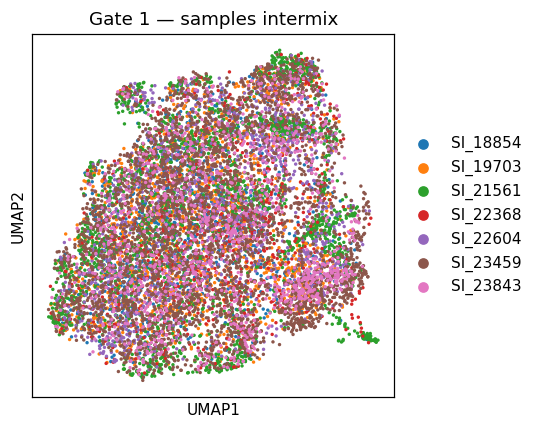

In [ ]:
# Gate-1 evidence: sample-coloured manifold on the house orientation
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(5, 4))
sc.pl.umap(plot, color='sample', size=20, frameon=True, show=False, ax=ax, title='Gate 1 — samples intermix')
fig.tight_layout(); plt.show()

### Save processed data
Coerce mixed-type object metadata to numeric where possible (else string) so the manifold is
h5ad-serializable; analysis-relevant columns are preserved.

In [ ]:
protect = {'sample','patient','lobe','celltype','cell_type','cell_subtype','cell_cycle_phase',
           'source','disease','mp_top','mp_assignment'}
for col_name in adata.obs.columns:
    if col_name in protect:
        adata.obs[col_name] = adata.obs[col_name].astype(str).astype('category'); continue
    col = adata.obs[col_name]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[col_name] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (11218, 23065)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)` horizontal strip, `size=30`) matching every other panel. Colour =
sample; intermixing across the strip is the Gate-1 batch-integration evidence, shown on the house
orientation (`X_umap_lin`) so this panel shares one orientation with 02/03/04.

saved samples.pdf | cells: 11218


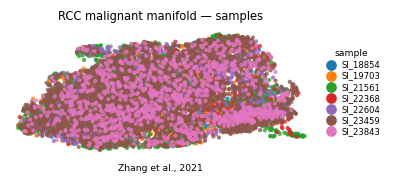

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('RCC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])